In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
classes=['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boat']

In [ ]:
x_train=x_train/255.0
x_test=x_test/255.0

In [ ]:
model=tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(64,activation='relu'),
    tf.keras.layers.Dense(10,activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.compile(optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

In [ ]:
history=model.fit(x_train,y_train,
                  epochs=5,validation_split=0.2)


Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8764 - loss: 0.3369 - val_accuracy: 0.8748 - val_loss: 0.3405
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8841 - loss: 0.3117 - val_accuracy: 0.8858 - val_loss: 0.3124
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8905 - loss: 0.2943 - val_accuracy: 0.8823 - val_loss: 0.3212
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8966 - loss: 0.2769 - val_accuracy: 0.8777 - val_loss: 0.3397
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9005 - loss: 0.2670 - val_accuracy: 0.8913 - val_loss: 0.3018


In [ ]:
loss,acc=model.evaluate(x_test,y_test)
print("test accuracy:",acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8804 - loss: 0.3347
test accuracy: 0.8804000020027161


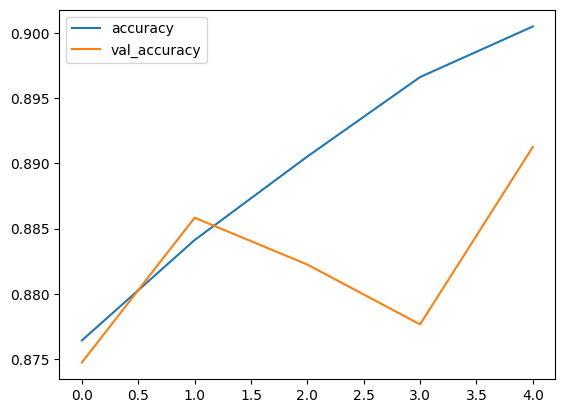

In [ ]:
plt.plot(history.history['accuracy'],label='accuracy')
plt.plot(history.history['val_accuracy'],label='val_accuracy')
plt.legend()
plt.show()

In [ ]:
pred=model.predict(x_test[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step


actual: Ankle boat
predicted: Ankle boat


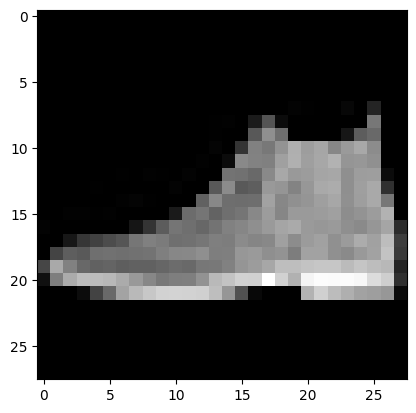

actual: Pullover
predicted: Pullover


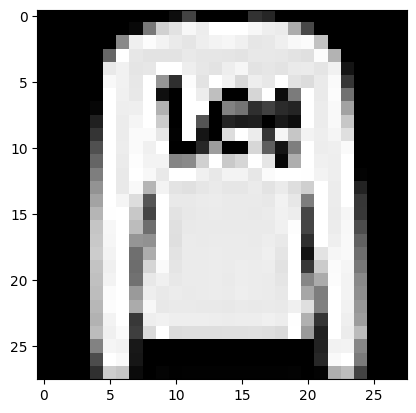

actual: Trouser
predicted: Trouser


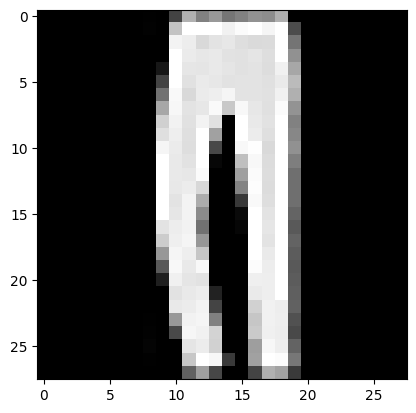

actual: Trouser
predicted: Trouser


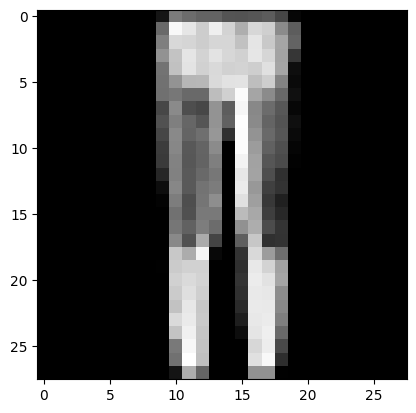

actual: Shirt
predicted: Shirt


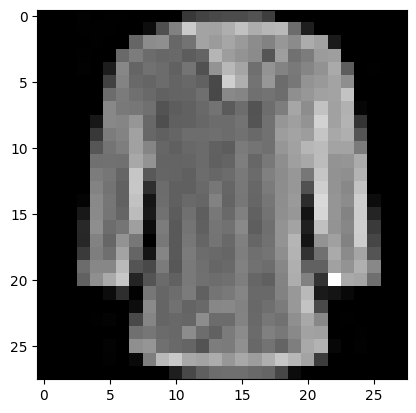

In [ ]:
for i in range(5):
  print("actual:",classes[y_test[i]])
  print("predicted:",classes[np.argmax(pred[i])])
  plt.imshow(x_test[i],cmap='gray')
  plt.show()